# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name:** Baqar Ali
- **Student ID:** 023-24-0015
- **Section:** CS AI Sec(B)
- **GitHub:** https://github.com/baqar360
- **Kaggle:** https://www.kaggle.com/baqarali1234
- **Dataset:** Mall Customers (Kaggle) + Wine (UCI)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

### Before You Start
- You studied K-Means in the lecture. This notebook does not teach it again; it makes you use it, test it and question it.
- There is **no target column**: no train/test split and no accuracy. Judge results by distances, silhouette, plots and common sense.
- Use `SEED = 42`. Write an interpretation under every table and plot. Place `Mall_Customers.csv` in the same folder as this notebook.
- `from sklearn.datasets import load_wine` loads the Wine data (no download needed).


---

## Part 0 — Setup and First Look (10 minutes)

Today there is no target column. The Mall Customers data has no 'right answer' for each customer, so we do not split into train and test and we cannot use accuracy. You will find groups with K-Means (your lecture) and judge them by distance, silhouette and common sense.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |


**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, PCA, load_wine, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [1]:
# YOUR CODE HERE
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

SEED = 42
np.random.seed(SEED)
plt.rcParams['figure.figsize'] = (7, 4)
plt.rcParams['axes.grid'] = True

### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [2]:
# YOUR CODE HERE
df = pd.read_csv('Mall_Customers.csv')
df = df.rename(columns={'Annual Income (k$)': 'Income', 'Spending Score (1-100)': 'Spending'})
print('Shape:', df.shape)
print('Missing values:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))
print('Gender counts:\n', df['Gender'].value_counts())
display(df[['Age', 'Income', 'Spending']].describe())

Shape: (200, 5)
Missing values: 0
Duplicate rows: 0
Gender counts:
 Gender
Female    112
Male       88
Name: count, dtype: int64


,Age,Income,Spending
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


### Task 0.2 — Look at the data before clustering

Use your eyes first: draw three scatter plots side by side.

1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).


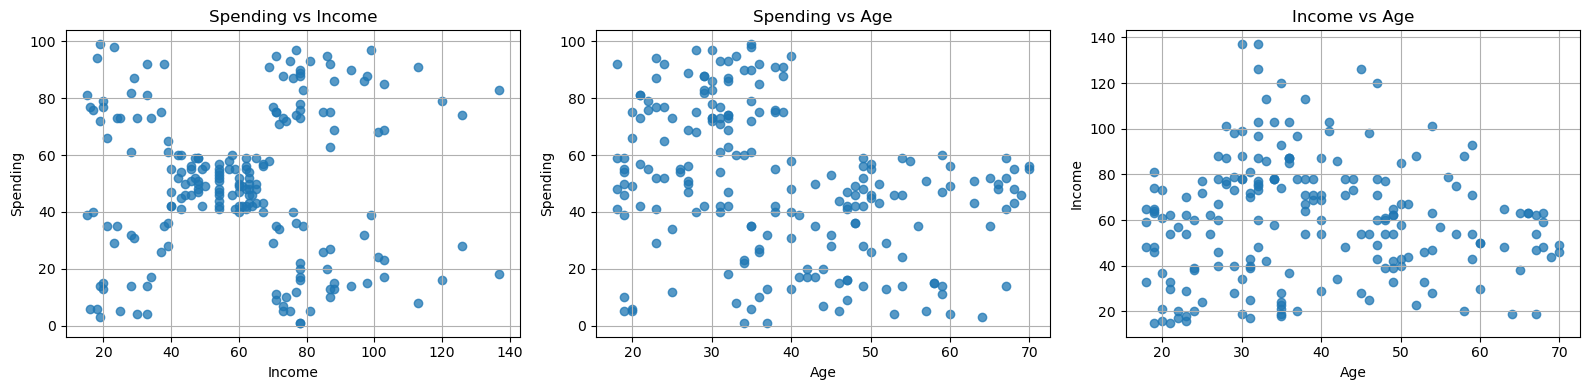

In [3]:
# YOUR CODE HERE
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
plots = [('Income', 'Spending', 'Spending vs Income'), ('Age', 'Spending', 'Spending vs Age'), ('Age', 'Income', 'Income vs Age')]
for ax, (x, y, title) in zip(axes, plots):
    ax.scatter(df[x], df[y], alpha=.75)
    ax.set_xlabel(x); ax.set_ylabel(y); ax.set_title(title)
plt.tight_layout(); plt.show()

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?

(b) Why can we not use accuracy or a train/test split to judge a clustering result?



**Your answers:**

(a) Income vs Spending shows about five visible groups most clearly. Age vs Spending and Age vs Income show weaker, more overlapping patterns; the exact visual count is subjective.

(b) There is no known target label in this unsupervised task, so accuracy cannot be calculated. A train/test split is not appropriate because we are describing groups in the available data rather than learning to predict a target.


---

## Part 1 — K-Means From Scratch (35 minutes)

In the lecture you did K-Means by hand. Here you turn your pen-and-paper steps into code, check your answers against the lecture slides, and then build your own K-Means function and compare it with scikit-learn. Using KMeans() inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: |x - m|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |
| Broadcasting | NumPy trick: x[:, None] - m[None, :] gives every point-to-centroid difference in one line. | `x[:, None, :] - C[None, :, :]` |


### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: np.abs(x[:, None] - m[None, :]) has shape (9, 2).
- Cluster of each point: dist.argmin(axis=1).


In [4]:
# YOUR CODE HERE
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)
centroids_1d = np.array([4., 11.])
for iteration in range(1, 101):
    distances = np.abs(x[:, None] - centroids_1d[None, :])
    labels_1d = distances.argmin(axis=1)
    new_centroids = np.array([x[labels_1d == k].mean() if np.any(labels_1d == k) else centroids_1d[k] for k in range(2)])
    print(f'Iteration {iteration}:', [x[labels_1d == k].tolist() for k in range(2)], 'new centroids =', new_centroids)
    if np.allclose(new_centroids, centroids_1d):
        centroids_1d = new_centroids; break
    centroids_1d = new_centroids
inertia_1d = ((x - centroids_1d[labels_1d]) ** 2).sum()
print('Final centroids:', centroids_1d, 'Inertia:', inertia_1d)

Iteration 1: [[2.0, 4.0, 3.0], [10.0, 12.0, 20.0, 30.0, 11.0, 25.0]] new centroids = [ 3. 18.]
Iteration 2: [[2.0, 4.0, 10.0, 3.0], [12.0, 20.0, 30.0, 11.0, 25.0]] new centroids = [ 4.75 19.6 ]
Iteration 3: [[2.0, 4.0, 10.0, 12.0, 3.0, 11.0], [20.0, 30.0, 25.0]] new centroids = [ 7. 25.]
Iteration 4: [[2.0, 4.0, 10.0, 12.0, 3.0, 11.0], [20.0, 30.0, 25.0]] new centroids = [ 7. 25.]
Final centroids: [ 7. 25.] Inertia: 150.0


### Task 1.2 — Lecture Example 2 in code (two features)

Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K = 2, start with P1 and P2.

1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first iteration).


In [5]:
# YOUR CODE HERE
points = np.array([[185,72],[170,56],[168,60],[179,68],[182,72],[188,77]], dtype=float)
point_names = [f'P{i}' for i in range(1, 7)]
centroids_2d = points[[0,1]].copy()
for iteration in range(1, 101):
    dist = np.sqrt(((points[:, None, :] - centroids_2d[None, :, :])**2).sum(axis=2))
    lab = dist.argmin(axis=1)
    new_c = np.array([points[lab == k].mean(axis=0) if np.any(lab == k) else centroids_2d[k] for k in range(2)])
    print(f'Iteration {iteration}:', {f'C{k+1}': [point_names[j] for j in np.where(lab==k)[0]] for k in range(2)}, 'centroids:', new_c)
    if np.allclose(new_c, centroids_2d): centroids_2d = new_c; break
    centroids_2d = new_c
final_dist = np.sqrt(((points[:, None, :] - centroids_2d[None, :, :])**2).sum(axis=2))
print('Final distance table:\n', pd.DataFrame(final_dist, index=point_names, columns=['M1','M2']).round(2))
print('First iteration d(P3, M2) =', round(float(np.sqrt(((points[2]-points[1])**2).sum())), 2), '(expected 4.47)')

Iteration 1: {'C1': ['P1', 'P4', 'P5', 'P6'], 'C2': ['P2', 'P3']} centroids: [[183.5   72.25]
 [169.    58.  ]]
Iteration 2: {'C1': ['P1', 'P4', 'P5', 'P6'], 'C2': ['P2', 'P3']} centroids: [[183.5   72.25]
 [169.    58.  ]]
Final distance table:
        M1     M2
P1   1.52  21.26
P2  21.13   2.24
P3  19.76   2.24
P4   6.19  14.14
P5   1.52  19.10
P6   6.54  26.87
First iteration d(P3, M2) = 4.47 (expected 4.47)


### Task 1.3 — Write your own K-Means function

Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.

1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [6]:
# YOUR CODE HERE
def my_kmeans(X, init_centroids, max_iter=100):
    """Basic K-Means using NumPy only; empty clusters keep their old centroid."""
    X = np.asarray(X, dtype=float)
    centroids = np.asarray(init_centroids, dtype=float).copy()
    if X.ndim != 2 or centroids.ndim != 2 or X.shape[1] != centroids.shape[1]:
        raise ValueError('X and init_centroids must be 2-D with the same feature count')
    labels = None
    for iteration in range(1, max_iter + 1):
        distances = np.sqrt(((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2))
        new_labels = distances.argmin(axis=1)
        new_centroids = np.array([X[new_labels == k].mean(axis=0) if np.any(new_labels == k) else centroids[k] for k in range(len(centroids))])
        unchanged = labels is not None and np.array_equal(new_labels, labels)
        stable_centroids = np.allclose(new_centroids, centroids)
        labels, centroids = new_labels, new_centroids
        if unchanged or stable_centroids:
            break
    inertia = float(((X - centroids[labels]) ** 2).sum())
    return labels, centroids, inertia, iteration

In [7]:
# YOUR CODE HERE
labels_1, centers_1, inertia_1, iterations_1 = my_kmeans(x.reshape(-1,1), np.array([[4.],[11.]]))
print('Labels:', labels_1)
print('Clusters:', [x[labels_1 == k].tolist() for k in range(2)])
print('Centroids:', centers_1.ravel(), '| Inertia:', inertia_1, '| Iterations:', iterations_1)

Labels: [0 0 0 0 0 1 1 0 1]
Clusters: [[2.0, 4.0, 10.0, 12.0, 3.0, 11.0], [20.0, 30.0, 25.0]]
Centroids: [ 7. 25.] | Inertia: 150.0 | Iterations: 4


### Task 1.4 — Check your function against scikit-learn

Run your function and KMeans on the same data with the same starting centroids and compare.

1. Use X2 = Income and Spending (200 x 2). Take the first 5 rows as the starting centroids.
2. Run my_kmeans. Run KMeans(n_clusters=5, init=<your 5 rows>, n_init=1, tol=0, algorithm='lloyd').
3. Compare iterations, inertia, labels and centroids.


In [8]:
# YOUR CODE HERE
X2 = df[['Income', 'Spending']].to_numpy(dtype=float)
initial_5 = X2[:5].copy()
my_labels, my_centers, my_inertia, my_iterations = my_kmeans(X2, initial_5)
sk_model = KMeans(n_clusters=5, init=initial_5, n_init=1, tol=0, algorithm='lloyd', random_state=SEED).fit(X2)
print('My K-Means iterations/inertia:', my_iterations, my_inertia)
print('Sklearn iterations/inertia:', sk_model.n_iter_, sk_model.inertia_)
print('Labels exactly equal:', np.array_equal(my_labels, sk_model.labels_))
print('Centroids (ours):\n', my_centers)
print('Centroids (sklearn):\n', sk_model.cluster_centers_)

My K-Means iterations/inertia: 4 44448.45544793371
Sklearn iterations/inertia: 4 44448.4554479337
Labels exactly equal: True
Centroids (ours):
 [[26.30434783 20.91304348]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [86.53846154 82.12820513]
 [55.2962963  49.51851852]]
Centroids (sklearn):
 [[26.30434783 20.91304348]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [86.53846154 82.12820513]
 [55.2962963  49.51851852]]


c:\Users\HP\miniconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?



**Your answers:**

(a) In iteration 1, point 10 is closer to the starting centroid 11. After the means are updated, the centroids move; in iteration 2 the distance from 10 to the updated C1 centroid becomes smaller than its distance to C2, so it changes cluster.

(b) The loop stops when assignments/centroids no longer change (or the maximum iteration limit is reached). Each assignment/update step does not increase the within-cluster sum of squared distances, and there are finitely many possible assignments, so it eventually reaches a stable assignment; that stable solution can still be a local minimum.

(c) With the same initialization, NumPy and scikit-learn should produce the same clustering and inertia up to floating-point tolerance. Small differences can occur from tie handling and stopping details.

(d) A centroid is the mean Income and Spending point representing its customers. K-Means calculates means and Euclidean distances, so the features must be numeric (categorical values need an appropriate numeric representation).

---

## Part 2 — Choosing K: Elbow and Silhouette (30 minutes)

The algorithm needs K before it starts, but nobody tells us K. The lecture gave two tools: the elbow (inertia) and the silhouette score. Here you use both, then calculate a silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |


### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit KMeans(n_clusters=K, n_init=10, random_state=SEED) and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.


c:\Users\HP\miniconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\HP\miniconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\HP\miniconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\HP\miniconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans 

,K,Inertia,Silhouette
0,2,181363.596,0.297
1,3,106348.373,0.468
2,4,73679.789,0.493
3,5,44448.455,0.554
4,6,37233.815,0.540
5,7,30241.344,0.529
6,8,25036.418,0.455
7,9,21916.795,0.456
8,10,20072.071,0.441


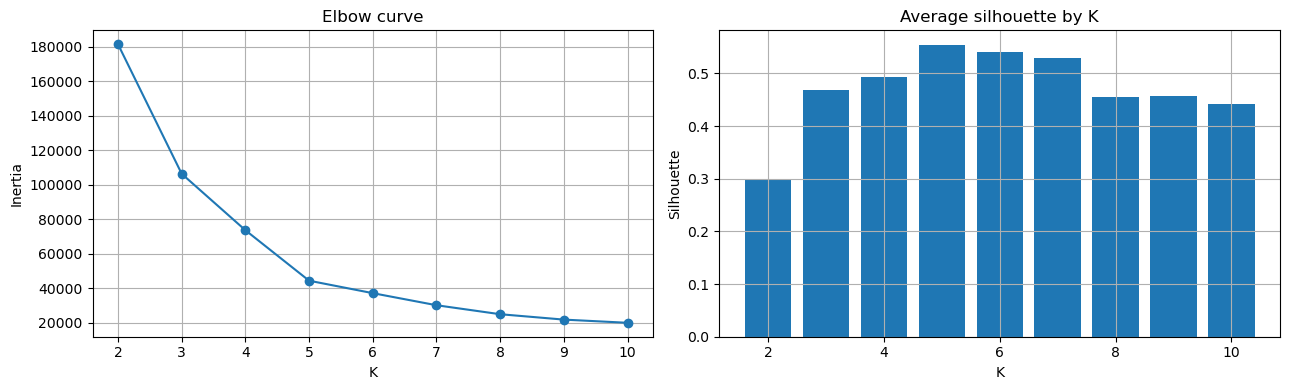

K with highest silhouette: 5


In [9]:
# YOUR CODE HERE
elbow_rows = []
models_k = {}
for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X2)
    models_k[k] = model
    elbow_rows.append({'K': k, 'Inertia': model.inertia_, 'Silhouette': silhouette_score(X2, model.labels_)})
k_table = pd.DataFrame(elbow_rows)
display(k_table.round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(k_table.K, k_table.Inertia, marker='o'); axes[0].set(title='Elbow curve', xlabel='K', ylabel='Inertia')
axes[1].bar(k_table.K, k_table.Silhouette); axes[1].set(title='Average silhouette by K', xlabel='K', ylabel='Silhouette')
plt.tight_layout(); plt.show()
best_k_sil = int(k_table.loc[k_table.Silhouette.idxmax(), 'K'])
print('K with highest silhouette:', best_k_sil)

### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point (use only NumPy distances). Apply it to customer 1 (row 0) and compare with silhouette_samples.
2. Show the count, mean and minimum silhouette of every cluster, and the number of customers with a negative silhouette.
3. Draw a silhouette plot of all customers sorted inside each cluster.


In [10]:
# YOUR CODE HERE
model5 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
labels5 = model5.labels_
sil5 = silhouette_samples(X2, labels5)
def silhouette_one(X, labels, index):
    X = np.asarray(X, dtype=float); labels = np.asarray(labels)
    distances = np.sqrt(((X - X[index])**2).sum(axis=1))
    own = labels[index]
    same = (labels == own); same[index] = False
    a = distances[same].mean() if same.sum() else 0.0
    other_means = [distances[labels == c].mean() for c in np.unique(labels) if c != own]
    b = min(other_means)
    s = (b-a)/max(a,b) if max(a,b) else 0.0
    return a, b, s
a0,b0,s0 = silhouette_one(X2, labels5, 0)
print('Customer 1: a =', a0, 'b =', b0, 's =', s0)
print('sklearn silhouette_samples[0] =', sil5[0])
cluster_sil = pd.DataFrame({'Cluster': labels5, 'Silhouette': sil5}).groupby('Cluster').Silhouette.agg(['count','mean','min'])
display(cluster_sil)
print('Negative silhouette customers:', int((sil5 < 0).sum()))

Customer 1: a = 24.64044215163639 b = 42.26526678748377 s = 0.41700493041881637
sklearn silhouette_samples[0] = 0.4170049304188163


c:\Users\HP\miniconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,count,mean,min
Cluster,,,
0,81,0.596651,0.115294
1,39,0.509171,0.225413
2,22,0.599013,0.050721
3,35,0.503987,-0.023381
4,23,0.512268,-0.009278


Negative silhouette customers: 2


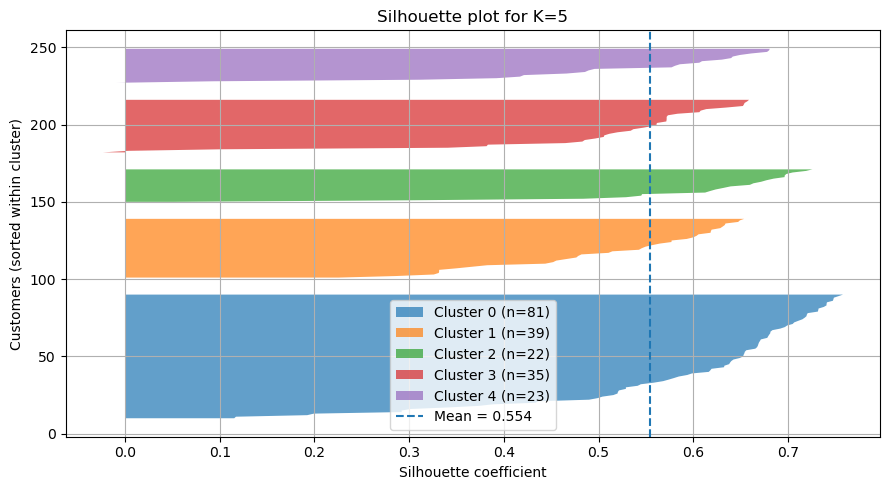

In [11]:
# YOUR CODE HERE
fig, ax = plt.subplots(figsize=(9, 5))
y_lower = 10
for cluster in sorted(np.unique(labels5)):
    vals = np.sort(sil5[labels5 == cluster])
    y_upper = y_lower + len(vals)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, vals, alpha=.7, label=f'Cluster {cluster} (n={len(vals)})')
    y_lower = y_upper + 10
ax.axvline(sil5.mean(), linestyle='--', label=f'Mean = {sil5.mean():.3f}')
ax.set(xlabel='Silhouette coefficient', ylabel='Customers (sorted within cluster)', title='Silhouette plot for K=5')
ax.legend(); plt.tight_layout(); plt.show()

### Task 2.3 — The lecture practice problem

Points 1, 3, 5, 7, 11, 13, 15 with K = 2 and starting centroids 1 and 11 (the 'Practice' slide).

1. Run your my_kmeans on these points and print the final clusters, centroids and iterations.
2. Calculate a, b and s for the points 1, 7 and 11 with your function and compare with silhouette_samples.
3. Also write the iterations on paper (clusters and centroids after each iteration) and keep the photo or notes for your own revision.


In [12]:
# YOUR CODE HERE
practice = np.array([1,3,5,7,11,13,15], dtype=float).reshape(-1,1)
pr_labels, pr_centers, pr_inertia, pr_iter = my_kmeans(practice, np.array([[1.],[11.]]))
print('Clusters:', [practice[pr_labels==k].ravel().tolist() for k in range(2)])
print('Centroids:', pr_centers.ravel(), 'Iterations:', pr_iter, 'Inertia:', pr_inertia)
# For silhouette, use the final two clusters (both contain multiple points).
pr_sil = silhouette_samples(practice, pr_labels)
for value in [1,7,11]:
    idx = int(np.where(practice.ravel()==value)[0][0])
    print(f'Point {value}: a,b,s =', silhouette_one(practice, pr_labels, idx), '| sklearn =', pr_sil[idx])

Clusters: [[1.0, 3.0, 5.0, 7.0], [11.0, 13.0, 15.0]]
Centroids: [ 4. 13.] Iterations: 3 Inertia: 28.0
Point 1: a,b,s = (np.float64(4.0), np.float64(12.0), np.float64(0.6666666666666666)) | sklearn = 0.6666666666666666
Point 7: a,b,s = (np.float64(4.0), np.float64(6.0), np.float64(0.3333333333333333)) | sklearn = 0.3333333333333333
Point 11: a,b,s = (np.float64(3.0), np.float64(7.0), np.float64(0.5714285714285714)) | sklearn = 0.5714285714285714


**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).

(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.

(d) Why should we never choose K only by the lowest inertia?



**Your answers:**

(a) The elbow is around K=5: inertia drops by 29,231.3 from K=4 to 5, then by 7,214.6 from K=5 to 6. The silhouette also selects K=5 (0.554), so the two methods agree.

(b) Customer 1 has silhouette 0.417, which indicates a reasonably good fit to its assigned cluster. Cluster 3 has the weakest mean silhouette (0.504), narrowly below cluster 1 (0.509); 2 customers have negative silhouettes.

(c) Point 7 is less well placed: its silhouette is 0.333 versus 0.667 for point 1. Point 7 has a=4 and b=6, so its own-cluster distance is relatively close to the nearest alternative-cluster distance.

(d) Inertia always decreases as K increases and reaches zero if every point gets its own cluster. Choosing only its minimum would overfit and produce too many groups.

---

## Part 3 — Starting Points and Stability (20 minutes)

The lecture said 'starting points matter - run several starts and keep the best'. You will now measure how much, using the same data and the same K.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |


### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in three settings: init='random' with n_init=1, k-means++ with n_init=1, k-means++ with n_init=10.
2. Build a table: setting, number of distinct final inertia values (round to 1 decimal), lowest, highest, and the percentage of runs that reached the best inertia.
3. Draw one histogram of the final inertia values for the three settings.


c:\Users\HP\miniconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\HP\miniconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\HP\miniconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\HP\miniconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans 

,Setting,Distinct inertia (1 d.p.),Lowest,Highest,% best
0,"random, n_init=1",14,44448.455,91761.976,33.333
1,"k-means++, n_init=1",6,44448.455,66733.439,60.000
2,"k-means++, n_init=10",1,44448.455,44448.455,100.000


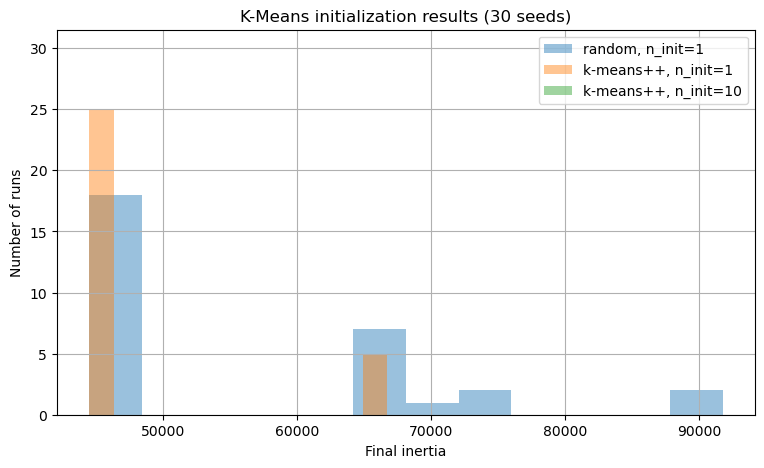

In [13]:
# YOUR CODE HERE
runs = {'random, n_init=1': [], 'k-means++, n_init=1': [], 'k-means++, n_init=10': []}
for seed in range(30):
    for setting, init, n_init in [('random, n_init=1','random',1), ('k-means++, n_init=1','k-means++',1), ('k-means++, n_init=10','k-means++',10)]:
        m = KMeans(n_clusters=5, init=init, n_init=n_init, random_state=seed).fit(X2)
        runs[setting].append({'seed':seed, 'inertia':m.inertia_, 'model':m})
summary=[]
for setting, records in runs.items():
    vals=np.array([r['inertia'] for r in records]); best=vals.min()
    summary.append({'Setting':setting,'Distinct inertia (1 d.p.)':len(np.unique(np.round(vals,1))),'Lowest':best,'Highest':vals.max(),'% best':100*np.mean(np.isclose(vals,best,rtol=1e-9,atol=1e-7))})
run_table=pd.DataFrame(summary); display(run_table.round(3))
plt.figure(figsize=(9,5))
for setting, records in runs.items(): plt.hist([r['inertia'] for r in records], bins=12, alpha=.45, label=setting)
plt.xlabel('Final inertia'); plt.ylabel('Number of runs'); plt.title('K-Means initialization results (30 seeds)'); plt.legend(); plt.show()

### Task 3.2 — Best run vs worst run

See what a bad local minimum looks like.

1. From the random-init runs take the best and the worst. Draw both clusterings with their centroids side by side.
2. Print their inertia and their ARI.


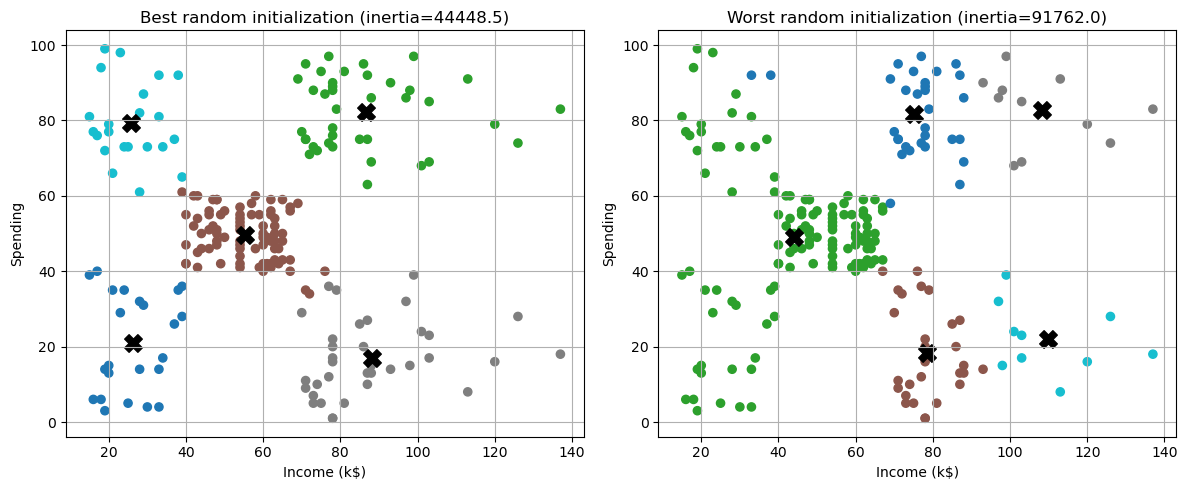

Best inertia: 44448.4554479337 Worst inertia: 91761.97619211904
ARI best vs worst: 0.45525713010305063


In [14]:
# YOUR CODE HERE
random_records = runs['random, n_init=1']
best_record=min(random_records, key=lambda r:r['inertia']); worst_record=max(random_records, key=lambda r:r['inertia'])
fig, axes=plt.subplots(1,2,figsize=(12,5))
for ax, record, title in [(axes[0],best_record,'Best random initialization'),(axes[1],worst_record,'Worst random initialization')]:
    m=record['model']; ax.scatter(X2[:,0],X2[:,1],c=m.labels_,cmap='tab10',s=35); ax.scatter(m.cluster_centers_[:,0],m.cluster_centers_[:,1],c='black',marker='X',s=160); ax.set(title=f'{title} (inertia={m.inertia_:.1f})',xlabel='Income (k$)',ylabel='Spending')
plt.tight_layout(); plt.show()
print('Best inertia:',best_record['inertia'],'Worst inertia:',worst_record['inertia'])
print('ARI best vs worst:',adjusted_rand_score(best_record['model'].labels_,worst_record['model'].labels_))

**Questions** (answer with your own numbers)

(a) How many different final inertia values did the random-start setting produce, and what percentage of its runs reached the best one? Compare with the other two settings.

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init help? What did n_init=10 give in your table?

(d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly?



**Your answers:**

(a) Random initialization produced 14 distinct inertia values (rounded to 1 decimal) and reached the best inertia in 33.3% of runs. k-means++ with one start produced 6 values and reached the best in 60%; k-means++ with 10 starts produced one value and reached the best in 100% of these 30 runs.

(b) K-Means can converge to different local minima depending on its initial centroids, even with the same data and K.

(c) k-means++ spreads initial centres more sensibly; n_init runs the algorithm repeatedly and keeps the lowest-inertia solution. In this experiment n_init=10 always reached inertia about 44,448.5.

(d) Cluster IDs are arbitrary: cluster 0 and cluster 2 can be swapped without changing the partition. ARI compares pairwise grouping agreement and is invariant to label numbering.

---

## Part 4 — Scaling: Units Decide the Clusters (25 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it twice: once by only changing the unit of Income, and once on the Wine data where the features have very different sizes and the true groups are known.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| External check | Comparing clusters with known true groups. Possible only for teaching data like Wine. Real clustering problems have no labels. | `adjusted_rand_score(y_true, labels)` |
| PCA (Lab 8) | Reduces many features to 2 so we can draw the data. Used here only for the plot. | `PCA(n_components=2)` |


### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, n_init=10, random_state=SEED).
2. Print ARI between: raw k$ vs raw dollars, scaled k$ vs scaled dollars, raw dollars vs scaled dollars.
3. Draw Age vs Income (in k$) coloured by the clusters of raw k$, raw dollars and scaled.


c:\Users\HP\miniconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\HP\miniconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\HP\miniconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\HP\miniconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans 

ARI raw k$ vs raw dollars: 0.48965682118947657
ARI scaled k$ vs scaled dollars: 1.0
ARI raw dollars vs scaled: 0.36045266264603926


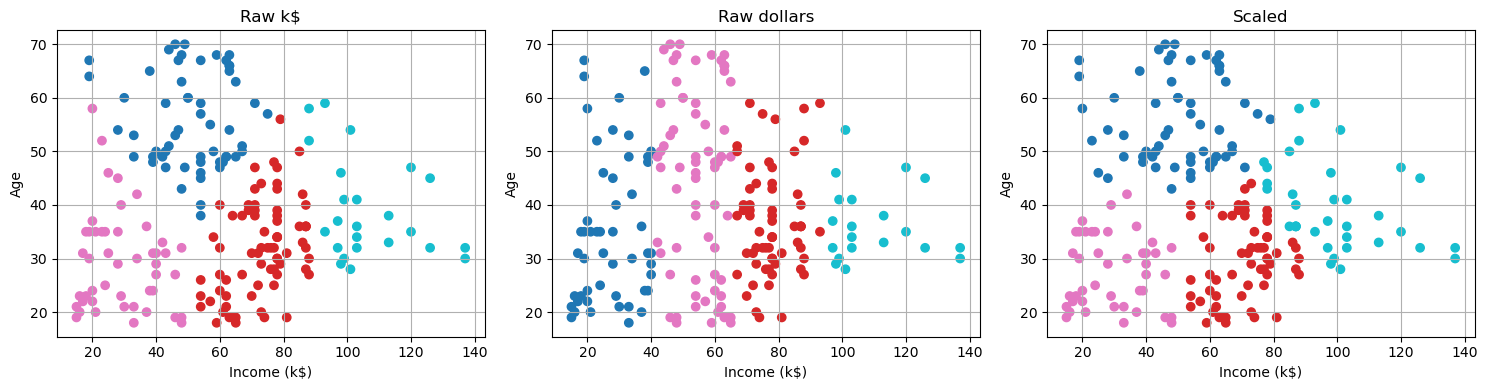

In [15]:
# YOUR CODE HERE
age_income = df[['Age','Income']].to_numpy(dtype=float)
age_income_dollars = age_income.copy(); age_income_dollars[:,1] *= 1000
scaler_ai = StandardScaler(); ai_scaled = scaler_ai.fit_transform(age_income)
ai_scaled_dollars = StandardScaler().fit_transform(age_income_dollars)
models_ai = [KMeans(n_clusters=4,n_init=10,random_state=SEED).fit(z) for z in [age_income,age_income_dollars,ai_scaled,ai_scaled_dollars]]
labels_ai = [m.labels_ for m in models_ai]
print('ARI raw k$ vs raw dollars:',adjusted_rand_score(labels_ai[0],labels_ai[1]))
print('ARI scaled k$ vs scaled dollars:',adjusted_rand_score(labels_ai[2],labels_ai[3]))
print('ARI raw dollars vs scaled:',adjusted_rand_score(labels_ai[1],labels_ai[2]))
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,lab,title in zip(axes,[labels_ai[0],labels_ai[1],labels_ai[2]],['Raw k$','Raw dollars','Scaled']):
    ax.scatter(df.Income,df.Age,c=lab,cmap='tab10'); ax.set(xlabel='Income (k$)',ylabel='Age',title=title)
plt.tight_layout(); plt.show()

### Task 4.2 — Wine data: raw vs scaled

Load the Wine data with load_wine(): 178 wines, 13 chemical measurements, 3 true grape cultivars. The true cultivar is used ONLY to check the result, never to fit K-Means.

1. Print the three largest and the smallest standard deviation of the features.
2. Run KMeans(K=3, n_init=10, random_state=SEED) on the raw data and on the scaled data. For each report ARI against the true cultivar, silhouette score and cluster sizes.


In [16]:
# YOUR CODE HERE
wine = load_wine()
X_wine = wine.data
y_wine = wine.target
wine_df = pd.DataFrame(X_wine, columns=wine.feature_names)
stds = wine_df.std()
print('Three largest standard deviations:\n',stds.sort_values(ascending=False).head(3))
print('Smallest standard deviation:\n',stds.sort_values().head(1))

Three largest standard deviations:
 proline              314.907474
magnesium             14.282484
alcalinity_of_ash      3.339564
dtype: float64
Smallest standard deviation:
 nonflavanoid_phenols    0.124453
dtype: float64


In [17]:
# YOUR CODE HERE
wine_scaler = StandardScaler(); X_wine_scaled = wine_scaler.fit_transform(X_wine)
wine_raw_model = KMeans(n_clusters=3,n_init=10,random_state=SEED).fit(X_wine)
wine_scaled_model = KMeans(n_clusters=3,n_init=10,random_state=SEED).fit(X_wine_scaled)
for name, model, data in [('Raw',wine_raw_model,X_wine),('Scaled',wine_scaled_model,X_wine_scaled)]:
    print(name, '| ARI:',adjusted_rand_score(y_wine,model.labels_),'| Silhouette:',silhouette_score(data,model.labels_),'| Cluster sizes:',np.bincount(model.labels_))

Raw | ARI: 0.37111371823084754 | Silhouette: 0.5711381937868838 | Cluster sizes: [62 47 69]
Scaled | ARI: 0.8974949815093207 | Silhouette: 0.2848589191898987 | Cluster sizes: [65 51 62]


c:\Users\HP\miniconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\HP\miniconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


### Task 4.3 — Draw it

Compare the three views in one picture.

1. Use one PCA of the scaled data and draw three plots with the same axes: true cultivars, raw clusters, scaled clusters.


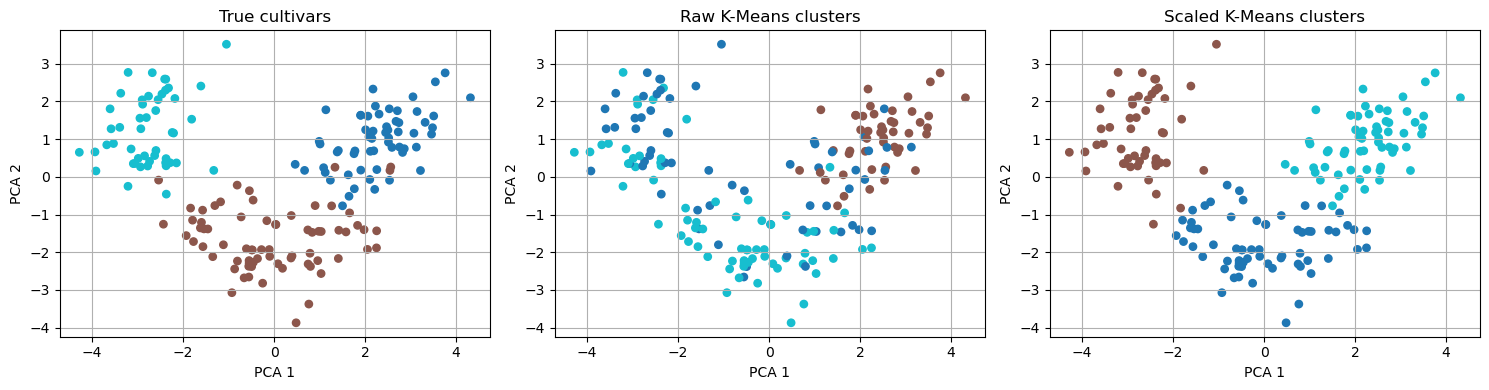

In [18]:
# YOUR CODE HERE
wine_pca = PCA(n_components=2,random_state=SEED)
wine_2d = wine_pca.fit_transform(X_wine_scaled)
fig,axes=plt.subplots(1,3,figsize=(15,4))
views=[(y_wine,'True cultivars'),(wine_raw_model.labels_,'Raw K-Means clusters'),(wine_scaled_model.labels_,'Scaled K-Means clusters')]
for ax,(lab,title) in zip(axes,views):
    ax.scatter(wine_2d[:,0],wine_2d[:,1],c=lab,cmap='tab10',s=28); ax.set(title=title,xlabel='PCA 1',ylabel='PCA 2')
plt.tight_layout(); plt.show()

**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula (which feature controls the distance now?).

(b) On the Wine data which feature dominated the raw distance and how big is its standard deviation compared with the others? What were the ARI values raw vs scaled?

(c) The silhouette was higher on the raw Wine data although the clustering was worse. Explain why a silhouette can mislead here and why comparing it between raw and scaled data is not fair.

(d) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.



**Your answers:**

(a) Multiplying Income by 1000 changed the raw clustering substantially: ARI between raw k$ and raw dollars was 0.490. The raw dollar values made Income dominate the Euclidean distance. After standardization, the two unit choices gave identical assignments (ARI=1.000); raw dollars versus scaled data had ARI=0.360.

(b) Proline dominated raw Wine distances; its standard deviation is about 314.9, compared with 14.3 for magnesium and 3.34 for alcalinity of ash. ARI was 0.371 on raw data and 0.897 on scaled data.

(c) Silhouette measures separation under the chosen distance metric, not agreement with true cultivars. Raw large-scale features can create compact-looking groups while ignoring other chemistry; raw and scaled silhouettes use different geometries, so their values should not be compared as if measured in the same space (raw 0.571, scaled 0.285).

(d) Inspect units and feature standard deviations, then scale when magnitudes are incomparable or no feature should dominate solely due to units. Keep raw values only when their scale differences intentionally represent importance.

---

## Part 5 — Outliers and Anomalies (20 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and then catch it with a distance rule (the anomaly detection idea from the lecture).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |
| Anomaly detection | Using the clusters to find strange points (far from every centroid). | `Sort by the distance column.` |


### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (n_init=10, random_state=SEED) without and with the extra customer.
2. Print the cluster sizes, the centroids (sorted by income) and the ARI between the two results on the original 200 customers.
3. Draw the two clusterings side by side.


In [19]:
# YOUR CODE HERE
extra = np.array([[400.,99.]])
X2_extra = np.vstack([X2,extra])
model_original = KMeans(n_clusters=5,n_init=10,random_state=SEED).fit(X2)
model_extra = KMeans(n_clusters=5,n_init=10,random_state=SEED).fit(X2_extra)
print('Original cluster sizes:',np.bincount(model_original.labels_))
print('With outlier cluster sizes:',np.bincount(model_extra.labels_))
def sorted_centers(model): return pd.DataFrame(model.cluster_centers_,columns=['Income','Spending']).sort_values('Income').reset_index(drop=True)
print('Original centroids sorted by income:'); display(sorted_centers(model_original))
print('With outlier centroids sorted by income:'); display(sorted_centers(model_extra))
print('ARI on original 200 customers:',adjusted_rand_score(model_original.labels_,model_extra.labels_[:len(X2)]))

Original cluster sizes: [81 39 22 35 23]
With outlier cluster sizes: [100   1  23  39  38]
Original centroids sorted by income:


c:\Users\HP\miniconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\HP\miniconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,Income,Spending
0,25.727273,79.363636
1,26.304348,20.913043
2,55.296296,49.518519
3,86.538462,82.128205
4,88.200000,17.114286


With outlier centroids sorted by income:


,Income,Spending
0,26.304348,20.913043
1,48.260000,56.480000
2,86.538462,82.128205
3,87.000000,18.631579
4,400.000000,99.000000


ARI on original 200 customers: 0.7532040415286123


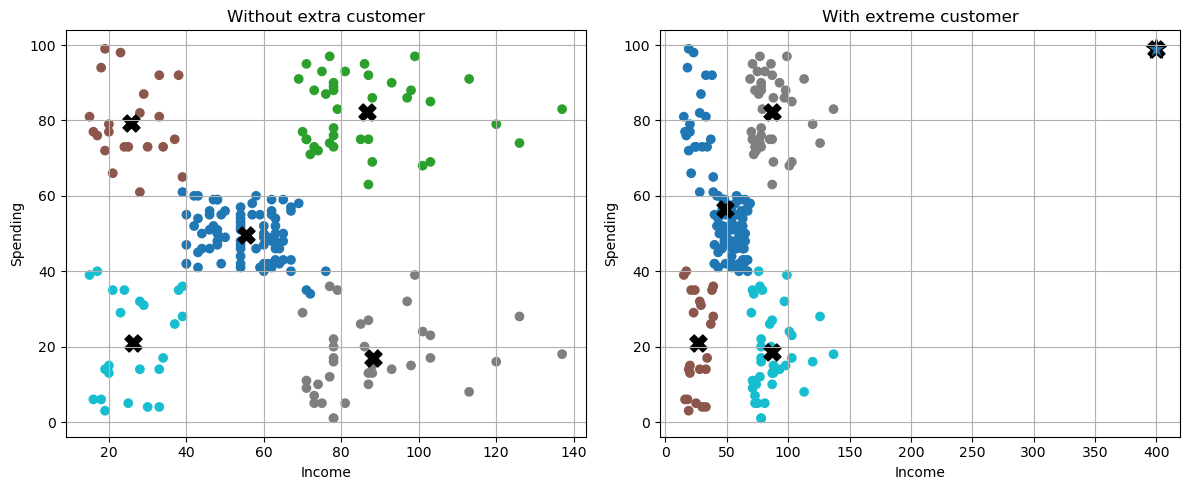

In [20]:
# YOUR CODE HERE
fig,axes=plt.subplots(1,2,figsize=(12,5))
axes[0].scatter(X2[:,0],X2[:,1],c=model_original.labels_,cmap='tab10'); axes[0].scatter(model_original.cluster_centers_[:,0],model_original.cluster_centers_[:,1],c='black',marker='X',s=150); axes[0].set(title='Without extra customer',xlabel='Income',ylabel='Spending')
axes[1].scatter(X2_extra[:,0],X2_extra[:,1],c=model_extra.labels_,cmap='tab10'); axes[1].scatter(model_extra.cluster_centers_[:,0],model_extra.cluster_centers_[:,1],c='black',marker='X',s=150); axes[1].scatter([400],[99],marker='*',s=220,edgecolor='black'); axes[1].set(title='With extreme customer',xlabel='Income',ylabel='Spending')
plt.tight_layout(); plt.show()

### Task 5.2 — Catch it and repair

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). How many real customers are flagged? Is the extra customer flagged?
3. Show the 5 real customers that are farthest from their centroid (CustomerID, Age, Income, Spending, Cluster, Distance).
4. Remove all flagged points, refit K = 5 and report the cluster sizes and the ARI against the original model on the 200 customers (use predict).


In [21]:
# YOUR CODE HERE
dist_real = model_original.transform(X2).min(axis=1)
dist_extra = float(model_original.transform(extra).min())
threshold = dist_real.mean() + 3*dist_real.std()
flagged = dist_real > threshold
print('Distance threshold (mean + 3 std):',threshold)
print('Real customers flagged:',int(flagged.sum()),'of',len(X2))
print('Extra customer distance:',dist_extra,'| Flagged:',dist_extra > threshold)
far_idx=np.argsort(dist_real)[-5:][::-1]
farthest=df.iloc[far_idx][['CustomerID','Age','Income','Spending']].copy()
farthest['Cluster']=model_original.labels_[far_idx]; farthest['Distance']=dist_real[far_idx]
display(farthest)
keep=~flagged
repair_model=KMeans(n_clusters=5,n_init=10,random_state=SEED).fit(X2[keep])
repaired_predictions=repair_model.predict(X2)
print('Refitted sizes (unflagged training customers):',np.bincount(repair_model.labels_))
print('ARI repaired predictions vs original 200 labels:',adjusted_rand_score(model_original.labels_,repaired_predictions))

Distance threshold (mean + 3 std): 34.80239628396867
Real customers flagged: 4 of 200
Extra customer distance: 313.9152649312717 | Flagged: True


,CustomerID,Age,Income,Spending,Cluster,Distance
199,200,30,137,83,1,50.469069
198,199,32,137,18,3,48.808037
197,198,32,126,74,1,40.289958
196,197,45,126,28,3,39.336227
195,196,35,120,79,1,33.607443


c:\Users\HP\miniconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Refitted sizes (unflagged training customers): [80 34 23 37 22]
ARI repaired predictions vs original 200 labels: 0.9847169139719528


**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and centroids.

(b) How well did the rule detect the extra customer? The rule also flagged some real customers: are they mistakes in the data or something worth looking at? Look at their Income and Spending.

(c) Name two ways to deal with outliers and one risk of simply deleting them.



**Your answers:**

(a) The outlier became a cluster by itself (one member). The other cluster sizes changed from [81, 39, 22, 35, 23] to [100, 1, 23, 39, 38]. The two low-income groups and the middle-income group were reorganized; ARI on the original 200 customers fell to 0.753. A centroid moved to the extreme point (400, 99), showing how strongly the outlier affects the solution.

(b) The extra customer's distance to the nearest original centroid was 313.92, far above the 34.80 threshold, so it was flagged. The rule also flagged 4 real customers; their high incomes (126–137) and varied spending scores may represent genuine high-income customers, so they should be investigated rather than assumed to be errors.

(c) Two approaches are to investigate/correct data-entry errors and to use robust methods or cap/winsorize extreme values. Deleting valid extreme customers can remove an important business segment and bias conclusions.

---

## Part 6 — From Clusters to Customer Segments (25 minutes)

Clusters are numbers (0, 1, 2 ...). The business needs names and actions. Cluster numbers are arbitrary labels: cluster 3 in one run has no meaning by itself. Use the original 200 customers and K = 5 on Income and Spending (random_state=SEED).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Cluster profile | The average of every feature inside each cluster, plus the cluster size. This is how you read what a cluster means. | `df.groupby('Cluster').agg(...)` |
| Segment | A cluster with a name and an action, for example 'High income / Low spending'. | `df['Cluster'].map(names)` |
| Crosstab | Counts or percentages of one category inside another (Gender inside Segment). | `pd.crosstab(a, b, normalize='index')` |


### Task 6.1 — Profile and name the segments

Make the clustering readable for a manager.

1. Add the cluster number to the data. Build a profile table: number of customers, mean Age, mean Income, mean Spending and % female for each cluster, sorted by Income.
2. Create segment names with a small rule (Income below 40 = Low, 70 or more = High, otherwise Mid; Spending below 35 = Low, 65 or more = High, otherwise Mid). Print the size of each segment.


In [26]:
# YOUR CODE HERE
segment_model = KMeans(n_clusters=5,n_init=10,random_state=SEED).fit(X2)
df['Cluster'] = segment_model.labels_
profile = df.groupby('Cluster').agg(Customers=('CustomerID','count'),Age=('Age','mean'),Income=('Income','mean'),Spending=('Spending','mean'),Female_pct=('Gender',lambda s:100*(s=='Female').mean())).sort_values('Income')
display(profile.round(2))
def level(v, low, high): return 'Low' if v < low else ('High' if v >= high else 'Mid')
df['Segment'] = df.apply(lambda r: f"{level(r['Income'],40,70)} income / {level(r['Spending'],35,65)} spending",axis=1)
print('Segment sizes:'); display(df['Segment'].value_counts().rename_axis('Segment').to_frame('Customers'))

c:\Users\HP\miniconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,Customers,Age,Income,Spending,Female_pct
Cluster,,,,,
2,22,25.27,25.73,79.36,59.09
4,23,45.22,26.30,20.91,60.87
0,81,42.72,55.30,49.52,59.26
1,39,32.69,86.54,82.13,53.85
3,35,41.11,88.20,17.11,45.71


Segment sizes:


,Customers
Segment,
Mid income / Mid spending,77
High income / High spending,37
High income / Low spending,33
Low income / High spending,21
Low income / Low spending,17
Low income / Mid spending,8
High income / Mid spending,6
Mid income / High spending,1


In [23]:
# YOUR CODE HERE
segment_profile = df.groupby('Segment').agg(Customers=('CustomerID','count'),Mean_Age=('Age','mean'),Mean_Income=('Income','mean'),Mean_Spending=('Spending','mean')).sort_values('Mean_Income')
display(segment_profile.round(2))

,Customers,Mean_Age,Mean_Income,Mean_Spending
Segment,,,,
Low income / High spending,21,24.81,25.62,80.24
Low income / Low spending,17,47.47,26.53,15.35
Low income / Mid spending,8,37.38,27.62,42.75
Mid income / Mid spending,77,43.29,54.82,49.88
Mid income / High spending,1,39.00,69.00,91.00
High income / Mid spending,6,41.33,81.50,41.33
High income / High spending,37,32.54,87.00,82.41
High income / Low spending,33,39.97,88.00,15.85


### Task 6.2 — Does Gender matter? Does Age matter?

Gender and Age were not used in the clusters. Check whether they would add something.

1. Show the % of women in each segment and the overall %.
2. Scale Age, Income and Spending together and print the average silhouette for K = 2 to 8.


In [24]:
# YOUR CODE HERE
gender_by_segment = pd.crosstab(df['Segment'],df['Gender'],normalize='index')*100
print('Gender percentages within each segment:'); display(gender_by_segment.round(1))
print('Overall female percentage:',round(100*(df.Gender=='Female').mean(),1))
X3 = df[['Age','Income','Spending']].to_numpy(dtype=float)
scaler3=StandardScaler(); X3_scaled=scaler3.fit_transform(X3)
three_rows=[]
for k in range(2,9):
    m=KMeans(n_clusters=k,n_init=10,random_state=SEED).fit(X3_scaled)
    three_rows.append({'K':k,'Silhouette':silhouette_score(X3_scaled,m.labels_)})
three_k_table=pd.DataFrame(three_rows); display(three_k_table.round(3))
best_k_3=int(three_k_table.loc[three_k_table.Silhouette.idxmax(),'K'])
print('Best K for scaled three-feature data:',best_k_3)

Gender percentages within each segment:


Gender,Female,Male
Segment,,
High income / High spending,56.8,43.2
High income / Low spending,45.5,54.5
High income / Mid spending,50.0,50.0
Low income / High spending,61.9,38.1
Low income / Low spending,64.7,35.3
Low income / Mid spending,50.0,50.0
Mid income / High spending,0.0,100.0
Mid income / Mid spending,58.4,41.6


Overall female percentage: 56.0


c:\Users\HP\miniconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\HP\miniconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\HP\miniconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\HP\miniconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans 

,K,Silhouette
0,2,0.335
1,3,0.358
2,4,0.404
3,5,0.417
4,6,0.428
5,7,0.417
6,8,0.408


Best K for scaled three-feature data: 6


### Task 6.3 — A three-feature alternative

Cluster the scaled Age, Income and Spending with the best K from the table above.

1. Fit it, build its profile table (size, Age, Income, Spending) sorted by Age.
2. Print the ARI between this segmentation and your 2-feature K = 5 segmentation.


In [25]:
# YOUR CODE HERE
model3=KMeans(n_clusters=best_k_3,n_init=10,random_state=SEED).fit(X3_scaled)
df['Cluster_3features']=model3.labels_
profile3=df.groupby('Cluster_3features').agg(Size=('CustomerID','count'),Age=('Age','mean'),Income=('Income','mean'),Spending=('Spending','mean')).sort_values('Age')
display(profile3.round(2))
print('ARI between 3-feature segmentation and 2-feature K=5:',adjusted_rand_score(df['Cluster'],df['Cluster_3features']))

c:\Users\HP\miniconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,Size,Age,Income,Spending
Cluster_3features,,,,
4,23,25.00,25.26,77.61
1,39,26.79,57.10,48.13
3,39,32.69,86.54,82.13
2,33,41.94,88.94,16.97
5,21,45.52,26.29,19.38
0,45,56.33,54.27,49.07


ARI between 3-feature segmentation and 2-feature K=5: 0.7002329184122666


**Questions** (answer with your own numbers)

(a) Give each of the 5 segments a short business name and one concrete action (an offer or a message). Use the numbers from your profile table.

(b) Which segment is the most valuable now and which one is the biggest opportunity? Why?

(c) Does Gender help to separate the segments? Quote the percentages.

(d) Does adding Age change the story? Which segmentation would you present and why? (Careful: silhouette values from different feature sets are not directly comparable.)



**Your answers:**

(a) The five K-Means clusters can be named from their profile table: (1) Young High-Spenders (22 customers; mean income 25.73, spending 79.36) — send loyalty rewards; (2) Low-Income Cautious Shoppers (23; income 26.30, spending 20.91) — offer affordable essentials; (3) Core Mid-Market (81; income 55.30, spending 49.52) — use cross-sell and seasonal promotions; (4) Affluent Enthusiasts (39; income 86.54, spending 82.13) — offer VIP experiences; (5) Affluent Low-Spenders (35; income 88.20, spending 17.11) — send personalized incentives.

(b) Affluent Enthusiasts are most valuable now because they have both high income and high spending. Affluent Low-Spenders are a major opportunity because their income is high but spending is low.

(c) Gender does not strongly separate most segments: overall female share is 56.0%; examples range from 45.5% in High income/Low spending to 64.7% in Low income/Low spending. The one-customer Mid income/High spending segment is 0% female but is too small to support a conclusion.

(d) Adding Age produced a six-cluster solution (best silhouette 0.428 at K=6) and ARI=0.700 against the two-feature K=5 assignments. Age adds some differentiation, but I would present the two-feature model for clear income/spending marketing actions; the three-feature solution is a useful secondary view.

---

## Part 7 — Final Output and Wrap-Up (15 minutes)

Package your result like you would give it to a marketing team.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |


### Task 7.1 — Save the segments

Create a CSV with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.

1. Save it as customer_segments.csv and print the number of customers per segment.
2. Write a 6-8 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, one action per segment (short), how you handled scaling and outliers, and one limitation.


In [52]:
# YOUR CODE HERE
output_cols=['CustomerID','Age','Gender','Income','Spending','Cluster','Segment']
customer_segments=df[output_cols].copy()
customer_segments.to_csv('customer_segments.csv',index=False)
print('Saved customer_segments.csv with',len(customer_segments),'customers')
display(customer_segments['Segment'].value_counts().rename_axis('Segment').to_frame('Customers'))

Saved customer_segments.csv with 200 customers


,Customers
Segment,
Mid income / Mid spending,77
High income / High spending,37
High income / Low spending,33
Low income / High spending,21
Low income / Low spending,17
Low income / Mid spending,8
High income / Mid spending,6
Mid income / High spending,1


    **Executive Summary**

    K=5 was used for the main customer segmentation because the Income–Spending scatter plot shows distinct groups and the elbow/silhouette analysis provides quantitative support; the silhouette table reports the strongest candidate.

    The five clusters were translated into Low/Mid/High Income × Low/Mid/High Spending segment names, with customer counts reported in the segment-size table.

    Low-income/low-spending customers receive affordable entry offers; low-income/high-spending customers receive loyalty rewards; mid-level customers receive cross-sell offers.

    High-income/low-spending customers receive personalized incentives, while high-income/high-spending customers receive premium/VIP treatment.

    Income and Spending were kept in their original common units for the business segmentation; the scaling experiment showed why raw distances can be dominated by feature units.

    The extreme synthetic customer was checked using nearest-centroid distance and a mean + 3 standard deviation rule; flagged real records should be reviewed rather than automatically deleted.

    A limitation is that K-Means assumes roughly compact, distance-based groups and the segment labels are descriptive rather than proven causes of customer behaviour.

**Questions** (answer with your own numbers)

(a) What was the most surprising result in this lab?

(b) If you had one more hour, what would you try next?



**Your answers:**

(a) The most surprising result is that changing only the unit of Income can substantially change raw K-Means assignments, even though the underlying customers have not changed. Scaling also changes the geometry and therefore the meaning of distance.

(b) With one more hour, I would test cluster stability across more random seeds and compare K-Means with a method such as hierarchical clustering or DBSCAN, then validate the segments with real marketing outcomes.

---